# EV ChargeOps — avaliação do motor de rateio e do módulo de IA

Este notebook é a evidência executada da Sprint 02. Ele usa o **mesmo código do back-end** (pasta `backend/app`)
sobre o banco gerado pelo simulador e responde quatro perguntas:

1. O motor de rateio reproduz o exemplo da Sprint 01 (unidade 1204, R$ 61,90)?
2. A detecção de anomalias encontra as sessões problemáticas antes que elas cheguem na fatura? O Isolation Forest
   acrescenta algo além das regras de negócio?
3. A previsão de demanda erra menos que uma média histórica simples?
4. A projeção da fatura do mês (mostrada ao morador) é confiável?

Para reexecutar: rode o simulador (`cd backend && python -m simulador.gerar_sessoes --ate 2026-10-13T15:00`) e depois
`python scripts/gerar_notebook.py` na raiz do repositório.

In [1]:
import json, os, subprocess, sys, tempfile
from datetime import date, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BACKEND = Path.cwd().parent / "backend"
sys.path.insert(0, str(BACKEND))

from sqlalchemy import create_engine
from app.database import PASTA_DADOS, SessionLocal
from app.rateio import ParametrosCalculo, SessaoRateio, calcular_rateio
from app.ia import servico as ia
from app.ia.previsao import montar_base_demanda, PrevisorDemanda, analisar_capacidade

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a94a0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e7ebef", "axes.axisbelow": True, "font.size": 10})
pd.set_option("display.max_colwidth", 90)

engine = create_engine(f"sqlite:///{PASTA_DADOS / 'evchargeops.db'}")
sessoes = pd.read_sql("select * from sessoes_recarga", engine, parse_dates=["inicio_em", "fim_em", "carga_completa_em"])
gabarito = pd.read_csv(PASTA_DADOS / "anomalias_injetadas.csv")
print(f"{len(sessoes)} sessões de {sessoes.inicio_em.min():%d/%m/%Y} a {sessoes.inicio_em.max():%d/%m/%Y}; "
      f"{len(gabarito)} anomalias injetadas pelo simulador")

197 sessões de 06/04/2026 a 12/10/2026; 11 anomalias injetadas pelo simulador


## 1. Visão geral dos dados simulados

In [2]:
por_mes = (sessoes.assign(mes=sessoes.inicio_em.dt.strftime("%Y-%m"))
           .groupby("mes").agg(sessoes=("id", "count"), kwh=("kwh_entregue", "sum"),
                                duracao_media_h=("duracao_min", lambda x: x.mean() / 60),
                                ociosidade_media_min=("minutos_ociosos", "mean")).round(1))
tentativas = pd.read_sql("select timestamp from tentativas_ocupado", engine, parse_dates=["timestamp"])
por_mes["chegadas_com_carregador_ocupado"] = tentativas.timestamp.dt.strftime("%Y-%m").value_counts().reindex(por_mes.index).fillna(0).astype(int)
por_mes

,sessoes,kwh,duracao_media_h,ociosidade_media_min,chegadas_com_carregador_ocupado
mes,,,,,
2026-04,21,263.9,3.8,74.6,3
2026-05,15,191.7,3.2,35.6,5
2026-06,29,477.5,4.2,67.4,11
2026-07,31,553.7,4.0,64.8,15
2026-08,31,502.8,3.7,41.3,13
2026-09,48,864.3,3.7,37.7,25
2026-10,22,391.7,3.6,40.4,10


In [3]:
sessoes.groupby(["status_final", "status_cobranca"]).size().rename("sessoes").to_frame()

sessoes
status_final status_cobranca         
concluida    descartada             3
             faturada             146
             liberada              14
             revisao_ia             2
falha        faturada               1
             revisao_ia             1
interrompida faturada              25
             liberada               4
             quarentena             1

## 2. Motor de rateio

O exemplo simulado da Sprint 01: 42 kWh, tarifa R$ 0,95, 5% de perdas, R$ 20,00 de taxa, sem ociosidade.

In [4]:
params = ParametrosCalculo(tarifa_kwh=0.95, perdas_percentual=5, taxa_infra=20.0, ociosidade_ativa=False)
r = calcular_rateio([SessaoRateio(1, 18.6, veiculo="Dolphin"), SessaoRateio(2, 23.4, veiculo="Kwid")], params)
display(pd.DataFrame(r.memoria))
print("Total:", r.valor_total)
assert str(r.valor_total) == "61.90"

,parcela,regra,valor
0,Energia,"42 kWh × R$ 0,95/kWh",39.9
1,Perdas técnicas,5% sobre a energia,2.0
2,Infraestrutura,Taxa fixa aprovada,20.0
3,Ociosidade,Regra de ociosidade desativada,0.0
4,Ajustes e créditos,Nenhum ajuste,0.0


Total: 61.90


Uma fatura real do banco (unidade A-1204, último mês fechado), com a memória de cálculo gravada no fechamento:

In [5]:
faturas = pd.read_sql("select f.*, u.bloco || '-' || u.numero as unidade from faturas f join unidades u on u.id = f.unidade_id", engine)
ultimo = faturas.mes_referencia.max()
f = faturas[(faturas.unidade == "A-1204") & (faturas.mes_referencia == ultimo)].iloc[0]
print(f"Unidade A-1204, {ultimo}: {f.qtd_sessoes} sessões, {f.kwh_total:.2f} kWh, total R$ {f.valor_total:.2f}")
pd.DataFrame(json.loads(f.memoria_calculo)["linhas"])

Unidade A-1204, 2026-09: 9 sessões, 127.41 kWh, total R$ 156.09


,parcela,regra,valor
0,Energia,"127,411 kWh × R$ 0,95/kWh",121.04
1,Perdas técnicas,5% sobre a energia,6.05
2,Infraestrutura,Taxa fixa aprovada,20.00
3,Ociosidade,"90 min acima da tolerância de 30 min × R$ 6,00/h",9.00
4,Ajustes e créditos,Nenhum ajuste,0.00


In [6]:
# conferência: a soma das faturas de cada mês bate com o rateio de cada sessão faturada?
resumo = faturas.groupby("mes_referencia").agg(unidades=("id", "count"), kwh=("kwh_total", "sum"), total=("valor_total", "sum")).round(2)
kwh_faturado = sessoes[sessoes.status_cobranca == "faturada"].assign(mes=lambda d: d.inicio_em.dt.strftime("%Y-%m")).groupby("mes").kwh_entregue.sum().round(2)
resumo["kwh_das_sessoes_faturadas"] = kwh_faturado
resumo

,unidades,kwh,total,kwh_das_sessoes_faturadas
mes_referencia,,,,
2026-04,12,263.93,466.48,263.93
2026-05,12,191.70,295.42,191.70
2026-06,12,477.54,736.55,477.54
2026-07,12,503.57,765.60,503.57
2026-08,12,502.80,750.25,502.80
2026-09,12,864.23,1125.77,864.23


## 3. Detecção de anomalias

Toda sessão encerrada passa por `avaliar_sessao_encerrada()`:

- **Regras de negócio** (kWh maior que a bateria, potência acima do limite, conectado sem carregar, falha, consumo
  muito acima do perfil, ociosidade longa);
- **Isolation Forest**, treinado no histórico e retreinado sempre que as faturas de um mês são geradas (no simulador,
  a cada virada de mês). Olha a qualidade elétrica da recarga em relação ao veículo: fração da bateria carregada,
  potência média ÷ esperada, potência máxima ÷ esperada e potência média ÷ máxima. 3 kW é normal para um híbrido
  plug-in e é sinal de defeito num carro que carrega a 7 kW. Sessões que a IA já apontou não entram no treino como
  exemplo de "normal", mesmo se o gestor liberar a cobrança. O modelo não retém uma sessão com potência média entre
  80% e 110% do esperado e pico até 110%: uma curva mais "reta" que o histórico, com a potência certa, não é defeito.

O conjunto de variáveis foi escolhido por teste (ver README, "Decisões técnicas"). Versões anteriores usavam tempo
ocioso, kWh e duração. A ociosidade dominava o modelo, e recargas curtas legítimas viravam alarme falso.

Severidade média ou alta **retém a cobrança** (status `revisao_ia`) até o gestor decidir. Sem RFID identificado a
sessão vai para `quarentena`. Abaixo, o que aconteceu com cada anomalia injetada no banco de demonstração:

In [7]:
def decisao(linha):
    # separa o que foi retido por regra do que foi retido pelo modelo
    motivos = json.loads(linha.anomalia_motivos) if isinstance(linha.anomalia_motivos, str) else []
    retida_regra = any(m["origem"] == "regra" and m["severidade"] in ("media", "alta") for m in motivos)
    retida_modelo = any(m["origem"] == "modelo" for m in motivos)
    return pd.Series({"retida_por_regra": retida_regra, "retida_pelo_modelo": retida_modelo,
                      "motivos": "; ".join(m["codigo"] for m in motivos)})

avaliadas = sessoes.join(sessoes.apply(decisao, axis=1))
# observação: a sessão de visitante (cartão desconhecido) não passa pela IA; vai direto para a quarentena.
# status_cobranca mostra o estado atual: nos meses fechados o gestor simulado já decidiu (faturada/descartada).

tab = gabarito.merge(avaliadas, left_on="sessao_id", right_on="id")
tab[["sessao_id", "tipo", "kwh_entregue", "potencia_media_kw", "score_anomalia", "motivos", "retida_por_regra", "retida_pelo_modelo", "status_cobranca"]].round(3)

,sessao_id,tipo,kwh_entregue,potencia_media_kw,score_anomalia,motivos,retida_por_regra,retida_pelo_modelo,status_cobranca
0,52,falha_carregador,13.063,7.13,NaN,falha_equipamento,True,False,faturada
1,70,salto_medidor,50.071,15.41,1.000,kwh_acima_da_bateria; acima_do_perfil_do_usuario; ociosidade_longa,True,False,descartada
2,85,sem_carregar,0.053,0.03,1.000,conectado_sem_carregar,True,False,descartada
3,109,cabo_defeituoso,3.961,1.43,0.989,padrao_atipico,False,True,faturada
4,160,cabo_defeituoso,4.265,1.43,0.992,padrao_atipico,False,True,faturada
5,163,sem_carregar,0.059,0.03,0.992,conectado_sem_carregar,True,False,descartada
6,166,pico_potencia,19.630,6.58,0.984,potencia_acima_do_limite,True,False,faturada
7,186,cartao_desconhecido,19.027,6.52,NaN,,False,False,quarentena
8,190,salto_medidor,47.066,40.93,0.994,kwh_acima_da_bateria; acima_do_perfil_do_usuario; ociosidade_longa,True,False,revisao_ia
9,194,falha_carregador,9.007,7.11,0.976,falha_equipamento,True,False,revisao_ia


### 3.1 Experimento ampliado

O banco de demonstração tem poucas anomalias. Para medir com mais segurança, rodamos o simulador mais 5 vezes
(sementes diferentes, sem o roteiro fixo e com o dobro de anomalias), cada uma num banco temporário, e comparamos:

- **Somente regras**: o que seria retido se não existisse o Isolation Forest;
- **Regras + Isolation Forest**: o comportamento real do sistema.

`Alarmes sem anomalia injetada` são sessões normais que o sistema reteve, ou seja, trabalho extra para o gestor.

In [8]:
def simular(semente):
    pasta = tempfile.mkdtemp(prefix=f"evco_exp_{semente}_")
    env = {**os.environ, "EVCO_DATA_DIR": pasta}
    env.pop("EVCO_DB_URL", None)
    subprocess.run([sys.executable, "-m", "simulador.gerar_sessoes", "--seed", str(semente), "--sem-roteiro",
                    "--taxa-anomalias", "0.14", "--ate", "2026-10-13T15:00"],
                   cwd=BACKEND, env=env, check=True, capture_output=True)
    eng = create_engine(f"sqlite:///{pasta}/evchargeops.db")
    s = pd.read_sql("select * from sessoes_recarga", eng)
    g = pd.read_csv(f"{pasta}/anomalias_injetadas.csv")
    s = s.join(s.apply(decisao, axis=1))
    s["injetada"] = s.id.isin(g.sessao_id)
    s = s.merge(g[["sessao_id", "tipo"]], left_on="id", right_on="sessao_id", how="left")
    s["semente"] = semente
    s["modelo_ativo"] = s.score_anomalia.notna()
    return s

experimento = pd.concat([simular(sem) for sem in [1, 2, 3, 4, 5]], ignore_index=True)
# o visitante sem cartão é tratado pela quarentena, não pela IA: fica fora desta medição
exp = experimento[experimento.tipo.ne("cartao_desconhecido")].copy()
exp["retida"] = exp.retida_por_regra | exp.retida_pelo_modelo
print(f"{len(exp)} sessões, {exp.injetada.sum()} anomalias injetadas (exceto cartão desconhecido)")

1078 sessões, 107 anomalias injetadas (exceto cartão desconhecido)


In [9]:
def metricas(df, coluna):
    inj = df[df.injetada]
    normais = df[~df.injetada]
    return pd.Series({
        "anomalias detectadas": f"{inj[coluna].sum()} de {len(inj)} ({inj[coluna].mean():.0%})",
        "alarmes sem anomalia injetada": f"{normais[coluna].sum()} de {len(normais)} ({normais[coluna].mean():.1%})",
    })

pd.DataFrame({
    "Somente regras": metricas(exp, "retida_por_regra"),
    "Regras + Isolation Forest": metricas(exp, "retida"),
})

,Somente regras,Regras + Isolation Forest
anomalias detectadas,85 de 107 (79%),94 de 107 (88%)
alarmes sem anomalia injetada,0 de 971 (0.0%),1 de 971 (0.1%)


In [10]:
por_tipo = (exp[exp.injetada].groupby("tipo")
            .agg(injetadas=("id", "count"), por_regra=("retida_por_regra", "sum"), sistema_completo=("retida", "sum"),
                 com_modelo_ja_treinado=("modelo_ativo", "sum")))
por_tipo

,injetadas,por_regra,sistema_completo,com_modelo_ja_treinado
tipo,,,,
cabo_defeituoso,16,0,9,12
falha_carregador,18,18,18,12
pico_potencia,22,22,22,18
salto_medidor,31,25,25,17
sem_carregar,20,20,20,12


**Leitura:** as regras pegam o que sabemos descrever (pico de potência, conectado sem carregar, falha e o salto de
medidor quando ele passa da bateria do carro). O **cabo com defeito** (potência muito baixa durante horas, mas kWh e
duração plausíveis) não tem regra própria e é o caso que o Isolation Forest acrescenta. Quando o defeito acontece antes
do primeiro treino (cold start, menos de 40 sessões no histórico), só as regras atuam, por isso parte desses casos
escapa. Saltos de medidor menores que a folga da bateria (ex.: +35 kWh num BYD Seal de 82,5 kWh) também passam:
para eles seria preciso comparar com a leitura do SEMS ou com o estado de carga do veículo.

Distribuição do score do modelo (percentil em relação ao histórico) para sessões normais e anômalas:

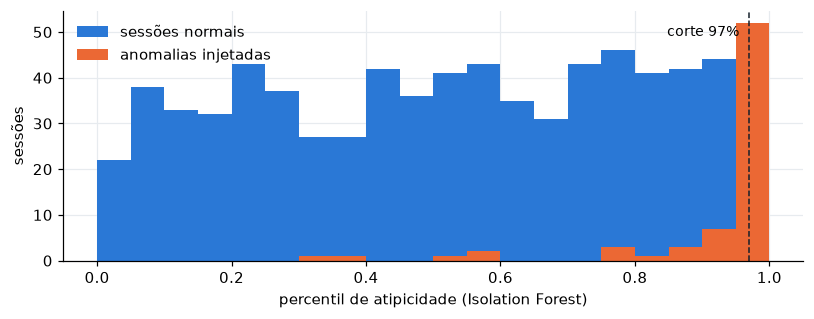

In [11]:
com_score = exp[exp.modelo_ativo]
fig, ax = plt.subplots(figsize=(7.5, 3))
bins = np.linspace(0, 1, 21)
ax.hist(com_score[~com_score.injetada].score_anomalia, bins=bins, color=AZUL, label="sessões normais")
ax.hist(com_score[com_score.injetada].score_anomalia, bins=bins, color=LARANJA, label="anomalias injetadas")
ax.axvline(0.97, color="#16202b", ls="--", lw=1)
ax.text(0.955, ax.get_ylim()[1] * 0.9, "corte 97%", ha="right", fontsize=9)
ax.set_xlabel("percentil de atipicidade (Isolation Forest)")
ax.set_ylabel("sessões")
ax.legend(frameon=False)
plt.tight_layout()

## 4. Previsão de demanda

Regressão de Poisson sobre chegadas por hora (sessões + tentativas com o carregador ocupado, sem contar duas vezes
quem tentou e conseguiu depois). Backtest: treina sem as últimas 4 semanas e compara com o que aconteceu.

In [12]:
db = SessionLocal()
agora = datetime(2026, 10, 13, 15)
base = montar_base_demanda(ia.chegadas(db), agora)
prev = PrevisorDemanda()
info = prev.treinar(base)
pd.Series(info).to_frame("valor")

,valor
treinado,True
semanas_historico,27
semanas_backtest,4
mae_por_hora_modelo,0.1348
mae_por_hora_baseline,0.126
erro_semanal_medio_pct_modelo,34.3
erro_semanal_medio_pct_baseline,48.8
crescimento_semanal_pct,2.76


,chegadas,previsto,baseline
semana,,,
23,14,10.5,8.4
24,18,10.7,8.4
25,22,10.9,8.4
26,14,11.1,8.4


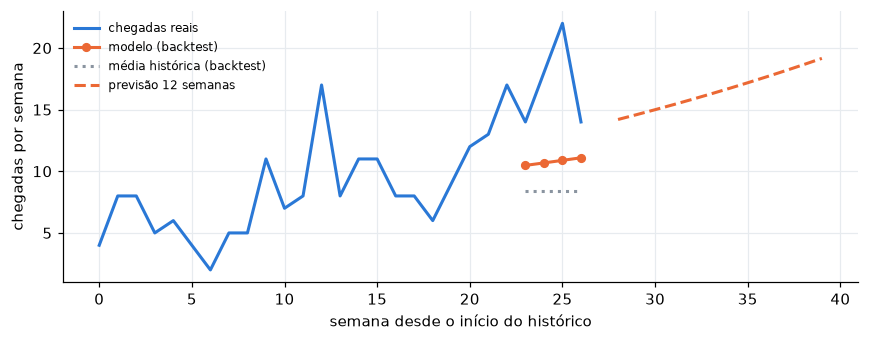

In [13]:
from app.ia.previsao import _matriz, SEMANAS_BACKTEST
from sklearn.linear_model import PoissonRegressor

n = int(base.semana.max()) + 1
corte = n - SEMANAS_BACKTEST
treino, teste = base[base.semana < corte], base[base.semana >= corte]
modelo = PoissonRegressor(alpha=1e-3, max_iter=2000).fit(_matriz(treino), treino.chegadas)
teste = teste.assign(previsto=modelo.predict(_matriz(teste)))
media_hist = treino.groupby(["dia", "hora"]).chegadas.mean()
teste["baseline"] = teste.set_index(["dia", "hora"]).index.map(media_hist).to_numpy()

semanal = base.groupby("semana").chegadas.sum()
sem_teste = teste.groupby("semana")[["chegadas", "previsto", "baseline"]].sum()
futuro = prev.prever(12)
sem_futuro = futuro[futuro.semanas_a_frente >= 1].groupby("semana").chegadas_previstas.sum()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(semanal.index, semanal.values, color=AZUL, lw=2, label="chegadas reais")
ax.plot(sem_teste.index, sem_teste.previsto, color=LARANJA, lw=2, marker="o", ms=5, label="modelo (backtest)")
ax.plot(sem_teste.index, sem_teste.baseline, color=CINZA, lw=2, ls=":", label="média histórica (backtest)")
ax.plot(sem_futuro.index, sem_futuro.values, color=LARANJA, lw=2, ls="--", label="previsão 12 semanas")
ax.set_xlabel("semana desde o início do histórico")
ax.set_ylabel("chegadas por semana")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
sem_teste.round(1)

In [14]:
duracao_h = ia.duracao_media_recente_h(db, agora)
capacidade = pd.DataFrame(analisar_capacidade(futuro, duracao_h, 1))
print(f"Duração média conectado (8 semanas): {duracao_h:.2f} h")
capacidade[capacidade.status != "ok"][["dia_nome", "faixa_nome", "ocupacao_proxima_semana", "ocupacao_fim_horizonte", "semanas_ate_exceder", "status"]]

Duração média conectado (8 semanas): 3.61 h


,dia_nome,faixa_nome,ocupacao_proxima_semana,ocupacao_fim_horizonte,semanas_ate_exceder,status
0,terça,noite (18h-24h),1.311,1.768,1.0,acima_capacidade
1,quarta,noite (18h-24h),1.076,1.451,1.0,acima_capacidade
2,quinta,noite (18h-24h),0.987,1.332,2.0,atencao


**Leitura:** por hora, o modelo erra um pouco mais que a média histórica (0,135 contra 0,126 chegada/hora no
banco de demonstração), porque as contagens são quase sempre 0 ou 1. Ele só ganha no total semanal (erro de 34%
contra 49%): a média histórica não enxerga o crescimento da frota, e o termo de tendência do modelo, sim. Por isso a
previsão é usada somada por faixa de 6 h, e é esse total que alimenta os alertas de capacidade do painel do gestor.

## 5. Projeção da fatura do mês (área do morador)

Teste retroativo: nos dias 8, 15 e 22 de cada mês fechado, quanto cada método dizia que a unidade consumiria no mês,
e quanto consumiu de fato? Três métodos candidatos:

- **histórico**: média diária das últimas 8 semanas para os dias que faltam;
- **regra de três**: consumo até agora × dias do mês ÷ dias decorridos;
- **mistura** (usada no sistema): ritmo do mês e média de 8 semanas, com peso proporcional aos dias decorridos.

No backtest abaixo a mistura tem o menor erro geral, mas não ganha em todos os cortes: no dia 8 erra um pouco mais que
o histórico (37,1 contra 36,7 kWh), porque o ritmo de uma semana ainda é ruidoso; nos dias 15 e 22 erra menos que o
histórico. No dia 15 a regra de três fica um pouco à frente (22,7 contra 23,5). A amostra é pequena (4 meses).

In [15]:
import calendar
from datetime import timedelta
validas = sessoes[sessoes.status_cobranca.isin(["faturada", "liberada"])].assign(dia=lambda d: d.inicio_em.dt.date)
meses_fechados = sorted(faturas.mes_referencia.unique())[-4:]
linhas = []
for mes in meses_fechados:
    ano, mm = map(int, mes.split("-"))
    dias_mes = calendar.monthrange(ano, mm)[1]
    for corte in (8, 15, 22):
        hoje = date(ano, mm, corte)
        for _, fat in faturas[faturas.mes_referencia == mes].iterrows():
            su = validas[validas.unidade_id == fat.unidade_id]
            no_mes = su[(su.inicio_em.dt.strftime("%Y-%m") == mes) & (su.dia <= hoje)].kwh_entregue.sum()
            janela = su[(su.dia >= hoje - timedelta(weeks=8)) & (su.dia <= hoje)].kwh_entregue.sum()
            media_8 = janela / (8 * 7 + 1)
            sistema = ia.projecao_kwh_mes(db, int(fat.unidade_id), mes, hoje)  # o mesmo código da área do morador
            linhas.append({"mes": mes, "dia": corte, "unidade": fat.unidade, "real": fat.kwh_total,
                           "historico": no_mes + media_8 * (dias_mes - corte),
                           "regra_de_tres": no_mes * dias_mes / corte,
                           "mistura_sistema": no_mes + sistema["kwh_previsto_restante"]})
bt = pd.DataFrame(linhas)
bt = bt[bt.real > 0]
erros = pd.DataFrame({c: (bt[c] - bt.real).abs() for c in ["historico", "regra_de_tres", "mistura_sistema"]}).assign(dia=bt.dia)
print("Erro médio absoluto (kWh) por dia do mês em que a projeção foi feita:")
tabela = erros.groupby("dia").mean().round(1)
tabela.loc["geral"] = erros.drop(columns="dia").mean().round(1)
tabela

Erro médio absoluto (kWh) por dia do mês em que a projeção foi feita:


,historico,regra_de_tres,mistura_sistema
dia,,,
8,36.7,46.6,37.1
15,27.8,22.7,23.5
22,15.8,14.1,13.8
geral,26.8,27.8,24.8


## 6. Conclusões

- O rateio reproduz exatamente o exemplo da Sprint 01 e a soma das faturas bate com as sessões faturadas.
- A IA participa do fluxo de cobrança: sessões anômalas ficam fora da fatura até a decisão do gestor. As regras
  cobrem os casos conhecidos e o Isolation Forest cobre o padrão que não tem regra (cabo/carregador degradado).
- A previsão de demanda erra um pouco mais que a média histórica por hora, mas menos no total semanal, que é o que
  indica quando um segundo ponto de recarga passa a ser necessário.
- A projeção da fatura usa a mistura entre o ritmo do mês e o histórico, que teve o menor erro geral no backtest
  acima. No dia 8 ela não supera o histórico e o erro ainda é grande, por isso a tela do morador apresenta o valor como
  estimativa.

**Limitações:** todos os dados são simulados. Com dados reais do HCA G2 os modelos precisam ser retreinados e o corte
de 97% recalibrado. O gabarito de anomalias existe só porque o simulador as injeta. Em produção, a precisão real vem
das decisões do gestor (descartar, liberar com crédito ou liberar sem ajuste), que já ficam registradas como eventos
de revisão: são os rótulos para medir quantas retenções eram mesmo problema e recalibrar o corte.